Customer Dataset:
    Customer_ID  Annual_Income  Spending_Score
0             1             15              85
1             2             16              88
2             3             17              82
3             4             18              90
4             5             20              86
5             6             40              65
6             7             42              70
7             8             45              68
8             9             48              72
9            10             50              66
10           11             70              45
11           12             72              50
12           13             75              48
13           14             78              52
14           15             80              46
15           16            100              20
16           17            105              25
17           18            110              18
18           19            115              22
19           20            120            

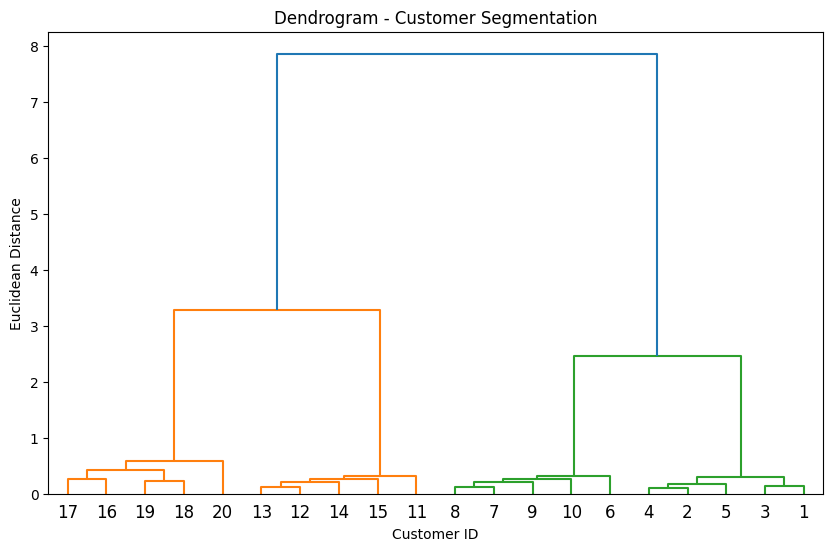


Customer Clusters:
    Customer_ID  Annual_Income  Spending_Score  Cluster
0             1             15              85        3
1             2             16              88        3
2             3             17              82        3
3             4             18              90        3
4             5             20              86        3
5             6             40              65        1
6             7             42              70        1
7             8             45              68        1
8             9             48              72        1
9            10             50              66        1
10           11             70              45        2
11           12             72              50        2
12           13             75              48        2
13           14             78              52        2
14           15             80              46        2
15           16            100              20        0
16           17            1

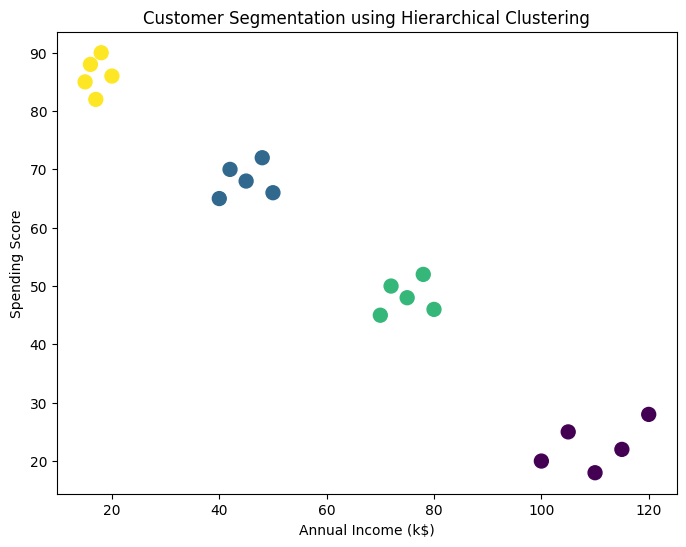


Cluster Interpretation:

Cluster: 0
Average Annual Income: 110.0
Average Spending Score: 22.6

Cluster: 1
Average Annual Income: 45.0
Average Spending Score: 68.2

Cluster: 2
Average Annual Income: 75.0
Average Spending Score: 48.2

Cluster: 3
Average Annual Income: 17.2
Average Spending Score: 86.2


In [1]:
# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Step 2: Create Customer Dataset
data = {
    'Customer_ID': range(1, 21),
    'Annual_Income': [
        15, 16, 17, 18, 20,
        40, 42, 45, 48, 50,
        70, 72, 75, 78, 80,
        100, 105, 110, 115, 120
    ],
    'Spending_Score': [
        85, 88, 82, 90, 86,
        65, 70, 68, 72, 66,
        45, 50, 48, 52, 46,
        20, 25, 18, 22, 28
    ]
}

df = pd.DataFrame(data)
print("Customer Dataset:")
print(df)

# Step 3: Select Features
X = df[['Annual_Income', 'Spending_Score']]
print("\nSelected Features:")
print(X.head())

# Step 4: Standardize Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Generate Linkage Matrix
linked = linkage(X_scaled, method='ward')

# Step 6: Plot Dendrogram
plt.figure(figsize=(10, 6))
dendrogram(
    linked,
    labels=df['Customer_ID'].values,
    distance_sort='descending'
)
plt.title("Dendrogram - Customer Segmentation")
plt.xlabel("Customer ID")
plt.ylabel("Euclidean Distance")
plt.show()

# Step 7: Apply Hierarchical Clustering
model = AgglomerativeClustering(
    n_clusters=4,
    metric='euclidean',
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)
df['Cluster'] = clusters

print("\nCustomer Clusters:")
print(df)

# Step 8: Visualize Clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    df['Annual_Income'],
    df['Spending_Score'],
    c=df['Cluster'],
    s=100
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using Hierarchical Clustering")
plt.show()

# Step 9: Interpret Each Cluster
print("\nCluster Interpretation:")

for cluster in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == cluster]

    avg_income = cluster_data['Annual_Income'].mean()
    avg_score = cluster_data['Spending_Score'].mean()

    print("\nCluster:", cluster)
    print("Average Annual Income:", round(avg_income, 2))
    print("Average Spending Score:", round(avg_score, 2))